In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [20]:
# Load the dataset
df = pd.read_csv("/kaggle/input/datasets/farhankarim11/polynomial-regrassion/manufacturing.csv")

# Display the first 5 rows
print("Dataset Head:")
display(df.head())

# Check for missing values and data types
print("\nDataset Info:")
df.info()

Dataset Head:


,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
0,209.762701,8.050855,1688.769167,44522.217074,9.229576e+06,99.999971
1,243.037873,15.812068,3842.931469,63020.764997,1.435537e+07,99.985703
2,220.552675,7.843130,1729.823314,49125.950249,1.072839e+07,99.999758
3,208.976637,23.786089,4970.736918,57128.881547,9.125702e+06,99.999975
4,184.730960,15.797812,2918.345014,38068.201283,6.303792e+06,100.000000



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3957 entries, 0 to 3956
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Temperature (°C)                3957 non-null   float64
 1   Pressure (kPa)                  3957 non-null   float64
 2   Temperature x Pressure          3957 non-null   float64
 3   Material Fusion Metric          3957 non-null   float64
 4   Material Transformation Metric  3957 non-null   float64
 5   Quality Rating                  3957 non-null   float64
dtypes: float64(6)
memory usage: 185.6 KB


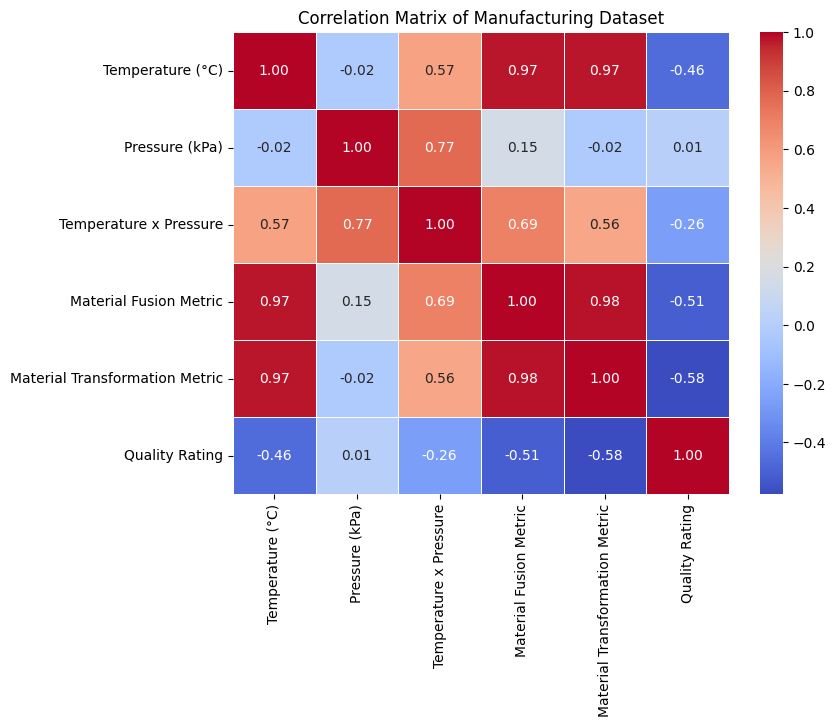

In [21]:
# Visualize correlation between variables
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Manufacturing Dataset')
plt.show()

In [22]:
# Select features and target variable
# Change features as needed, e.g., ['Temperature (°C)', 'Pressure (kPa)']
X = df[['Temperature (°C)', 'Pressure (kPa)']]
y = df['Quality Rating']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3957, 2)
Target shape: (3957,)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")

Training set size: 3165 rows
Testing set size: 792 rows


In [24]:
# Choose degree of polynomial (e.g., degree=2 or 3)
degree = 2

poly = PolynomialFeatures(degree=degree, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Scale features for better optimization performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

print(f"Transformed features shape (Degree {degree}): {X_train_scaled.shape}")

Transformed features shape (Degree 2): (3165, 5)


In [25]:
# Initialize and train Linear Regression on polynomial features
poly_reg_model = LinearRegression()
poly_reg_model.fit(X_train_scaled, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [26]:
# Make predictions on test data
y_pred = poly_reg_model.predict(X_test_scaled)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Model Performance (Degree {degree}):")
print(f"-----------------------------------")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"R-squared Score (R2):           {r2:.4f}")

Model Performance (Degree 2):
-----------------------------------
Root Mean Squared Error (RMSE): 10.4180
Mean Squared Error (MSE):       108.5342
R-squared Score (R2):           0.4684


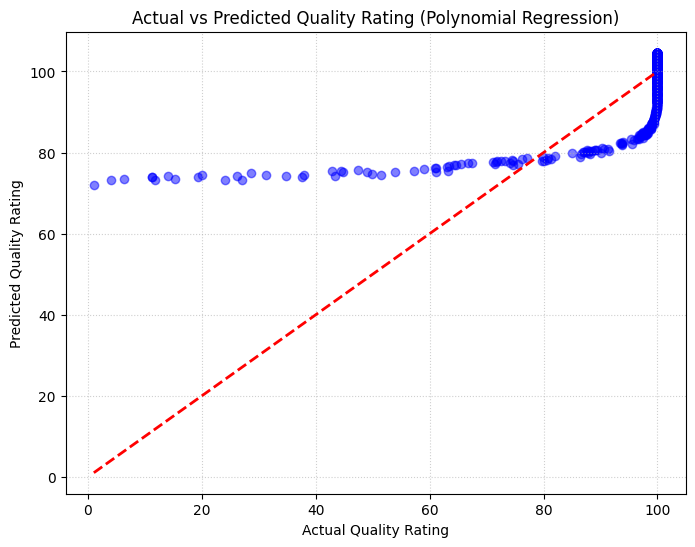

In [27]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', lw=2)
plt.xlabel('Actual Quality Rating')
plt.ylabel('Predicted Quality Rating')
plt.title('Actual vs Predicted Quality Rating (Polynomial Regression)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()